# 05 · EV pricing & specs

The project brief names four Thurro datasets. Three feed the models; **EV pricing & specs** has not been used anywhere. This notebook gives it a descriptive pass.

The files are weekly scraped listing prices, deduplicated to one row per variant per distinct price, with the window (`first_seen` → `last_seen`) the price held:

* `data/processed/ev_prices_car_variants.csv` — 604 rows, electric cars (4W)
* `data/processed/ev_prices_2w_variants.csv` — 50 rows, electric two-wheelers

Coverage is 2025-11 to 2026-09, eleven months. That is too short to model, so the question here is narrower: **did 4W EV prices fall while 4W demand rose?** The state siting model found that 4W share, not total EV share, is what lines up with where investment lands, so it matters what is behind 4W growth.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path('..') if Path('../data').exists() else Path('.')
FIG = ROOT / 'notebook-590' / 'figures'
FIG.mkdir(exist_ok=True)

BLUE, ORANGE, AQUA, GREY, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': GRID, 'axes.grid': True, 'axes.grid.axis': 'y',
                     'grid.color': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK2})

cars = pd.read_csv(ROOT / 'data/processed/ev_prices_car_variants.csv', parse_dates=['first_seen', 'last_seen'])
bikes = pd.read_csv(ROOT / 'data/processed/ev_prices_2w_variants.csv', parse_dates=['first_seen', 'last_seen'])
regs = pd.read_csv(ROOT / 'data/clean/registrations_segment_monthly.csv', parse_dates=['month'])
print('cars:', len(cars), 'rows,', cars['model'].nunique(), 'models,', cars['brand'].nunique(), 'brands')
print('2W:  ', len(bikes), 'rows,', bikes['model'].nunique(), 'models,', bikes['brand'].nunique(), 'brands')

cars: 604 rows, 75 models, 24 brands
2W:   50 rows, 12 models, 5 brands


## 1. Turn price windows into a monthly table

Each row says "this variant was listed at this price from `first_seen` to `last_seen`". Spreading it over the months it covers gives one row per variant per month. If a variant changed price inside a month, the later price is kept.

In [2]:
def to_monthly(prices):
    rows = []
    for _, r in prices.iterrows():
        for month in pd.period_range(r['first_seen'], r['last_seen'], freq='M'):
            rows.append({'month': month, 'brand': r['brand'], 'model': r['model'], 'variant': r['variant'],
                         'price': r['ex_showroom_price_inr'], 'battery_kwh': r['battery_kwh'],
                         'range_km': r['range_km'], 'first_seen': r['first_seen']})
    out = pd.DataFrame(rows).sort_values('first_seen')
    return out.drop_duplicates(['month', 'model', 'variant'], keep='last')

car_m = to_monthly(cars)
listed = car_m.groupby('month').agg(variants=('variant', 'count'), models=('model', 'nunique'),
                                     median_listed_price_lakh=('price', lambda s: s.median() / 1e5))
listed.round(1)

,variants,models,median_listed_price_lakh
month,,,
2025-11,232,56,22.1
2025-12,243,57,22.2
2026-01,248,58,22.1
2026-02,259,61,22.0
2026-03,281,63,22.2
2026-04,258,63,22.8
2026-05,271,61,22.3
2026-06,190,52,24.6
2026-07,202,56,24.4


**The listing set changes a lot from month to month** (190 to 288 variants), so the median listed price mostly tracks *which* cars were scraped, not what any car costs. Comparing the same variant with itself avoids that.

## 2. Same-variant price index

For every variant listed in two consecutive months, take the change in its log price. The average of those changes is the month's price change; chaining them gives an index (2025-11 = 100). This is the standard way to build a price index when the basket keeps changing.

In [3]:
wide = car_m.pivot_table(index='month', columns=['model', 'variant'], values='price')
monthly_change = np.log(wide).diff()              # NaN where a variant is missing either month
price_index = 100 * np.exp(monthly_change.mean(axis=1).fillna(0).cumsum())
pairs = monthly_change.notna().sum(axis=1)

# how many variants changed price at all, and by how much
first_last = cars.groupby(['model', 'variant'])['ex_showroom_price_inr'].agg(['first', 'last', 'count'])
changed = first_last[first_last['count'] > 1]
pct = changed['last'] / changed['first'] - 1
print('variants with more than one price:', len(changed), 'of', len(first_last))
print('median change for those: %+.1f%%, cuts: %d, rises: %d' % (100 * pct.median(), (pct < 0).sum(), (pct > 0).sum()))

r4 = regs[regs['vehicle_segment'] == '4W'].copy()
r4 = r4.set_index(r4['month'].dt.to_period('M'))['ev_registrations']
compare = pd.DataFrame({'price_index': price_index, 'variant_pairs': pairs,
                        'reg_4w': r4}).loc['2025-11':'2026-09']
compare['reg_4w_index'] = 100 * compare['reg_4w'] / compare['reg_4w'].iloc[0]
compare.round(1)

variants with more than one price: 152 of 398
median change for those: +1.3%, cuts: 2, rises: 142


,price_index,variant_pairs,reg_4w,reg_4w_index
month,,,,
2025-11,100.0,0.0,17205,100.0
2025-12,100.1,231.0,17316,100.6
2026-01,100.1,241.0,21154,123.0
2026-02,100.2,246.0,15923,92.5
2026-03,100.3,239.0,25628,149.0
2026-04,100.3,257.0,25408,147.7
2026-05,100.4,250.0,27748,161.3
2026-06,100.4,189.0,32631,189.7
2026-07,101.2,175.0,33480,194.6


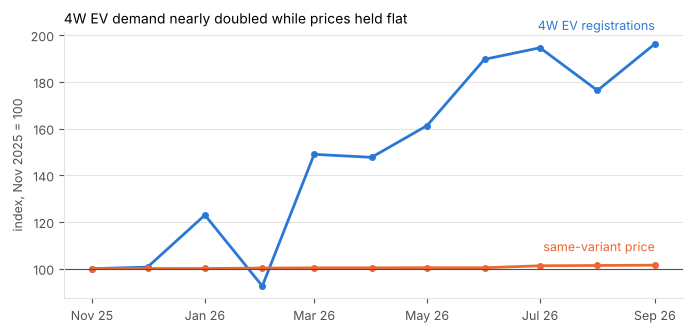

month-on-month correlation, registrations vs price: -0.17 (10 pairs, descriptive only)


In [4]:
x = compare.index.to_timestamp()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(x, compare['reg_4w_index'], color=BLUE, lw=2, marker='o', ms=4)
ax.plot(x, compare['price_index'], color=ORANGE, lw=2, marker='o', ms=4)
ax.axhline(100, color=INK2, lw=0.8)
ax.text(x[-1], compare['reg_4w_index'].iloc[-1] + 6, '4W EV registrations', color=BLUE, ha='right')
ax.text(x[-1], compare['price_index'].iloc[-1] + 6, 'same-variant price', color=ORANGE, ha='right')
ax.set_xticks(x[::2], [d.strftime('%b %y') for d in x[::2]])
ax.set_ylabel('index, Nov 2025 = 100')
ax.set_title('4W EV demand nearly doubled while prices held flat', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '05_price_index_vs_4w_registrations.png', dpi=160)
plt.show()

growth_corr = np.corrcoef(np.log(compare['reg_4w']).diff()[1:], np.log(compare['price_index']).diff()[1:])[0, 1]
print('month-on-month correlation, registrations vs price: %.2f (10 pairs, descriptive only)' % growth_corr)

## 3. If not price, what changed on the supply side?

Three things the listings can show: how many models are on sale, how many are new (first seen after the first scrape), and what the typical car offers (range, price per kWh of battery).

In [5]:
launch_month = cars.groupby('model')['first_seen'].min().dt.to_period('M')
new_models = launch_month[launch_month > launch_month.min()].value_counts().sort_index()

car_m['price_per_kwh'] = car_m['price'] / car_m['battery_kwh']
supply = pd.DataFrame({
    'models_listed': car_m.groupby('month')['model'].nunique(),
    'new_models_first_seen': new_models,
    'median_range_km': car_m.groupby('month')['range_km'].median(),
    'median_rs_per_kwh': car_m.groupby('month')['price_per_kwh'].median().round(0),
}).fillna({'new_models_first_seen': 0})
print('models first seen after the first scrape:', int(new_models.sum()))
print(sorted(launch_month[launch_month > launch_month.min()].index))
supply

models first seen after the first scrape: 19
['BMW i5 LWB', 'Citroen e-C3 X', 'Kia Syros EV', 'Lexus ES', 'Lexus ES Electric', 'Lotus Emeya', 'MG Hector Tomahawk EV', 'Mahindra XEV 9S', 'Mahindra XUV 3XO EV', 'Maruti Suzuki e Vitara', 'Maruti e Vitara', 'Mercedes-Benz CLA Electric', 'Tata Sierra EV', 'Tata Tiago EV 2022-2026', 'Tata Xpres T EV', 'Tesla Model Y', 'Toyota Urban Cruiser EBELLA', 'VinFast Limo Green', 'VinFast VF MPV 7']


,models_listed,new_models_first_seen,median_range_km,median_rs_per_kwh
2025-11,56,0.0,490.0,43464.0
2025-12,57,1.0,490.0,43454.0
2026-01,58,2.0,490.0,43403.0
2026-02,61,3.0,490.0,43152.0
2026-03,63,2.0,491.0,43475.0
2026-04,63,1.0,502.0,43717.0
2026-05,61,2.0,502.0,43541.0
2026-06,52,1.0,538.0,44645.0
2026-07,56,4.0,538.0,42249.0
2026-08,61,1.0,530.0,40651.0


## 4. The longer view: 4W is a growing share of the EV market

Registrations go back further than prices, so this places the eleven price months in context.

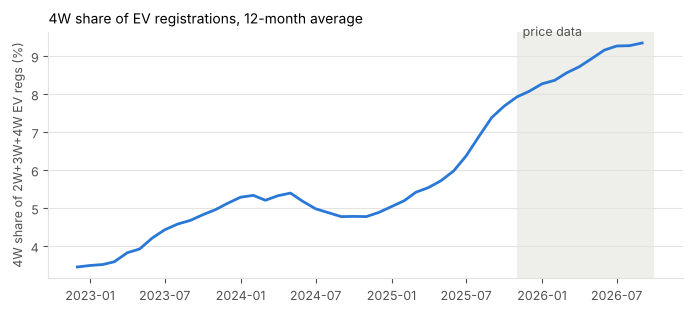

vehicle_segment,2W,3W,4W
month,,,
2022,63.0,33.5,3.4
2023,57.5,37.4,5.1
2024,60.5,34.7,4.8
2025,57.5,34.4,8.1
2026,63.0,27.2,9.9


In [6]:
seg = regs[regs['vehicle_segment'].isin(['2W', '3W', '4W'])]
seg = seg.pivot_table(index='month', columns='vehicle_segment', values='ev_registrations')
seg = seg.loc['2022-01-01':]
share = seg.div(seg.sum(axis=1), axis=0) * 100
share_12m = share.rolling(12).mean()      # smooths festive-season swings

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(share_12m.index, share_12m['4W'], color=BLUE, lw=2)
ax.axvspan(pd.Timestamp('2025-11-01'), pd.Timestamp('2026-09-30'), color=GRID, alpha=0.6, lw=0)
ax.text(pd.Timestamp('2025-11-15'), share_12m['4W'].max() * 1.02, 'price data', color=INK2)
ax.set_ylabel('4W share of 2W+3W+4W EV regs (%)')
ax.set_title('4W share of EV registrations, 12-month average', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '05_4w_share_of_ev_registrations.png', dpi=160)
plt.show()

yearly = seg.groupby(seg.index.year).sum()
(yearly.div(yearly.sum(axis=1), axis=0) * 100).round(1)

## 5. Two-wheelers: not enough data to say anything

The 2W file covers 12 models from 5 brands, and most rows are Bajaj Chetak variants. Some months have one model listed. That is not a sample of a market where the top sellers (Ola, TVS, Ather, Bajaj and many smaller makers) sell 150,000–200,000 units a month, so no 2W price trend is reported.

In [7]:
bike_m = to_monthly(bikes)
print(bikes['brand'].value_counts())
bike_m.groupby('month')['model'].nunique().rename('2W models listed')

brand
Bajaj            30
TVS              10
Yamaha            4
Honda             3
Royal Enfield     3
Name: count, dtype: int64


month
2025-11    8
2025-12    1
2026-01    1
2026-02    3
2026-03    3
2026-04    4
2026-05    4
2026-06    4
2026-07    5
2026-08    5
2026-09    2
Freq: M, Name: 2W models listed, dtype: int64

## What this says

1. **The 4W EV demand surge was not a price-cut story.** From November 2025 to September 2026, 4W EV registrations almost doubled (index 100 → 196) while the same-variant price index rose 1.5%. Of the 152 variants whose listed price changed, 142 went up and 2 went down. Month-to-month, price and registrations are unrelated (correlation −0.17 on 10 pairs).
2. **What changed was the supply side.** 19 model names appear for the first time in the window — a few are renames (two spellings of the Maruti e Vitara, for example), so call it about 15 launches, including the Maruti e Vitara, Tata Sierra EV, Mahindra XEV 9S, Kia Syros EV and Tesla Model Y. Median listed range rose from 490 to about 520–540 km at a flat price per kWh. More choice and longer range at the same price, not cheaper cars.
3. **4W is the part of the EV market that is changing.** Its share of 2W+3W+4W EV registrations was about 5% in 2023–2024 and is about 10% in 2026, a doubling, while 2W and 3W shares moved back and forth.

**For the storyline (act three: mix, not volume).** The models found that headline EV production does not lead investment, but the *composition* of the market does better: segment-mix features nationally, and 4W share in the state siting model. This notebook adds the demand-side picture behind that: the segment that is gaining share is 4W, its growth is driven by new models rather than lower prices, and 4W is the segment where carmakers' plant decisions (Maruti, Mahindra, Tata, Hyundai in the announcement file) are made. It is consistent with the mix result; it does not test it.

**Limits.** Eleven months, listing (ex-showroom) prices rather than transaction prices, and no sales weights — a variant that sells ten units counts the same as one that sells ten thousand. The 2W file is too thin to use. Nothing here is causal.